# Early-Stage Joint Energy Functional for OCT B-scan Denoising
### K-SVD sparse coding + second-order TGV in a single optimisation

This notebook implements **one joint energy** for OCT speckle suppression instead of fusing two
independently produced images in pixel space. The unknown clean B-scan $X$ is estimated together
with its sparse patch codes $\alpha$ and the TGV auxiliary field $p$:

$$
\min_{X,\alpha,p}\;
\underbrace{\tfrac12\|Y-X\|_2^2}_{\text{data fidelity}}
+\underbrace{\alpha_1\|\nabla X-p\|_1+\alpha_0\|\mathcal{E}(p)\|_1}_{\text{TGV}^2}
+\underbrace{\lambda\sum_{ij}\Big(\|R_{ij}X-D\alpha_{ij}\|_2^2+\mu\|\alpha_{ij}\|_0\Big)}_{\text{K-SVD patch prior}}
$$

* $Y$ — the raw single-shot B-scan (Duke SDOCT 2012), $X$ — the estimate, both in the normalised
  log domain $z=\log(1+Y/255)/\log 2\in[0,1]$ where multiplicative speckle is additive.
* $D\in\mathbb{R}^{64\times256}$ — the **pre-trained** global K-SVD dictionary shipped with the
  repository (`KSVD_OMP/outputs/checkpoints/global_dict.npz`). It is loaded, never re-trained.
* $R_{ij}X$ — the 8×8 patch at grid position $(i,j)$, $\alpha_{ij}$ its sparse code,
  $\mathcal{E}(p)=\tfrac12(\nabla p+\nabla p^{\top})$ the symmetrised gradient.

The problem is solved by **alternating minimisation with split-Bregman (ADMM) duals**:

| block | sub-problem | solver |
|---|---|---|
| $\alpha$ | $\min_\alpha \|R_{ij}X-D\alpha\|_2^2+\mu\|\alpha\|_0$ per patch | batched OMP (L0 budget $T$) |
| $X$ | quadratic in $X$ with data, patch-average and TGV dual terms | **exact FFT solve** (periodic, circulant) |
| $p,d,v,b$ | TGV$^2$ dual/shrinkage updates | isotropic soft-thresholding + FFT solve |

The $X$-block is diagonalised by the FFT because patches are extracted with wrap-around and stride
$s$, so $\sum_{ij}R_{ij}^{\top}R_{ij}=C\,I$ with $C=(8/s)^2$: the normal equations become
$\big(1+\gamma_1|\nabla|^2+2\lambda C\big)\hat X=\widehat{\text{rhs}}$, one inverse FFT per iteration.

Everything is benchmarked against the registered averaged scan $R$ of each subject: raw input,
standalone K-SVD, standalone TGV$^2$, late-stage pixel-space blending (the previous approach) and
the proposed joint estimate. Metrics: ROI PSNR, edge-band SSIM, Sobel EPI and the 10–90 % boundary
rise distance. **The averaged reference is itself a registered multi-frame average with its own
noise floor and residual motion blur**, so it is a reference, not a ground truth.

Runtime on the CPU-only environment used here: ≈ 1 s per joint iteration for a 530×970 B-scan
(OMP with a 1-atom budget dominates), ≈ 9 s for the standalone K-SVD pass and ≈ 6 s for TGV.

## 1 · Setup, paths and the pre-trained dictionary

In [1]:
import importlib.util
import json
import sys
import time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import ndimage
from scipy.signal import convolve2d
from skimage.feature import graycomatrix
from skimage.filters import threshold_otsu
from skimage.metrics import structural_similarity

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "image.cmap": "gray", "axes.grid": False,
                     "font.size": 9, "figure.facecolor": "white"})


def find_repo(start: Path | None = None) -> Path:
    '''Locate the repository root (the folder that holds the SDOCT dataset).'''
    p = Path.cwd() if start is None else Path(start)
    for cand in (p, *p.parents):
        if (cand / "Sparsity_SDOCT_DATASET_2012").is_dir():
            return cand
    raise FileNotFoundError("run this notebook from inside the complementary-fusion repository")


REPO = find_repo()
DATASET = REPO / "Sparsity_SDOCT_DATASET_2012"
DICT_PATH = REPO / "KSVD_OMP" / "outputs" / "checkpoints" / "global_dict.npz"
DICT_META = DICT_PATH.with_suffix(".json")
OUT_DIR = REPO / "Implementations" / "results_joint_energy"
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

PEAK = 255.0          # the dataset is 8-bit; every metric uses data_range = 255
LOG2 = float(np.log(2.0))   # log1p(255/255): the top of the normalised log domain

print("repository :", REPO)
print("outputs    :", OUT_DIR)

repository : /home/ananth/oct_denoising
outputs    : /home/ananth/oct_denoising/results_joint_energy


In [2]:
# ---------------------------------------------------------------------------------
# Central configuration. The solver hyper-parameters below are *defaults*; section 5
# re-selects (lam, alpha1, alpha0) on the validation subjects 13-14 and freezes them
# before the 17-subject benchmark.
# ---------------------------------------------------------------------------------
@dataclass(frozen=True)
class JointConfig:
    lam: float = 0.15        # weight of the per-patch K-SVD dictionary term
    alpha1: float = 0.08     # TGV weight on ||grad X - p||_1
    alpha0: float = 0.04     # TGV weight on ||E(p)||_1
    gamma1: float = 2.0      # split-Bregman penalty for grad X - p = d
    gamma2: float = 2.0      # split-Bregman penalty for E(p) = v
    mu: float = 1e-3         # L0 weight (the OMP budget T fixes the active set)
    sparsity: int = 1        # T = number of atoms per patch (L0 budget)
    patch: int = 8           # patch side (the dictionary is 8x8)
    stride: int = 2          # patch grid stride (2 -> C = 16, 4x cheaper than stride 1)
    max_iters: int = 40
    tol: float = 1e-5        # stopping rule: ||X_k - X_{k-1}|| / ||X_k||


CFG_DEFAULT = JointConfig()

# ---------------------------------------------------------------------------------
# The pre-trained dictionary: D in R^{64 x 256}, learned by K-SVD on averaged images.
# ---------------------------------------------------------------------------------
ckpt = np.load(DICT_PATH)
D = ckpt["D"].astype(np.float64)
meta = json.loads(DICT_META.read_text())
assert D.shape == (64, 256), D.shape
print(f"dictionary D : {D.shape}, dtype {D.dtype}")
print(f"atoms        : unit norm, min {np.linalg.norm(D, axis=0).min():.6f}, "
      f"max {np.linalg.norm(D, axis=0).max():.6f}")
print("checkpoint   :", {k: meta[k] for k in ("iter", "rmse", "patch_size", "n_atoms",
                                              "ksvd_sparsity", "n_patches")})

dictionary D : (64, 256), dtype float64
atoms        : unit norm, min 1.000000, max 1.000000
checkpoint   : {'iter': 20, 'rmse': 3.657896351566248, 'patch_size': 8, 'n_atoms': 256, 'ksvd_sparsity': 6, 'n_patches': 30000}


In [3]:
# ---------------------------------------------------------------------------------
# The 17 paired B-scans of the Duke SDOCT 2012 dataset.
# ---------------------------------------------------------------------------------
def list_cases() -> dict:
    '''{subject: (raw_path, averaged_path)} for the paired single-shot / averaged scans.'''
    cases = {}
    for sub in sorted(DATASET.iterdir()):
        if not sub.is_dir() or not sub.name.isdigit():
            continue
        raw = sorted(sub.glob("*Raw Image.tif"))
        avg = sorted(sub.glob("*Averaged Image.tif"))
        if raw and avg:
            cases[int(sub.name)] = (raw[0], avg[0])
    return cases


CASES = list_cases()
print("subjects:", sorted(CASES))


def load_pair(subject: int):
    '''(raw single-shot B-scan Y, registered averaged reference R) as float64 on [0, 255].'''
    raw_path, avg_path = CASES[subject]
    return (tifffile.imread(str(raw_path)).astype(np.float64),
            tifffile.imread(str(avg_path)).astype(np.float64))

subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


## 2 · Data and noise levels

Each subject provides a single-shot **raw** B-scan $Y$ and a registered multi-frame **averaged**
scan $R$ of the same retina. The averaged scan is the reference used for scoring; it has its own
noise floor (≈ 4 grey levels) and residual motion blur, which caps the attainable PSNR and makes
the measured edge width of the reference larger than the true optical edge.

In [4]:
stats = []
for s in sorted(CASES):
    Y, R = load_pair(s)
    stats.append({
        "subject": s, "shape": f"{Y.shape[0]}x{Y.shape[1]}",
        "raw p1/p99": f"{np.percentile(Y, 1):.0f}/{np.percentile(Y, 99):.0f}",
        "ref p1/p99": f"{np.percentile(R, 1):.0f}/{np.percentile(R, 99):.0f}",
        "raw std": round(float(Y.std()), 1), "ref std": round(float(R.std()), 1),
        "raw zeros %": round(100 * float((Y == 0).mean()), 2),
    })
stats_df = pd.DataFrame(stats)
print(stats_df.to_string(index=False))
stats_df.to_csv(OUT_DIR / "dataset_summary.csv", index=False)

 subject   shape raw p1/p99 ref p1/p99  raw std  ref std  raw zeros %
       1 520x970      0/200     34/175     44.4     28.5         4.61
       2 530x980      0/198     27/190     40.9     28.7         4.46
       3 508x960      0/184     40/162     40.6     27.0         4.70
       4 552x990      0/187     28/177     43.3     31.4         7.02
       5 550x950      0/178     25/163     42.0     29.2         8.68
       6 540x950      0/165     36/150     36.7     21.1         5.84
       7 530x980      0/173     29/159     38.5     24.5         5.62
       8 540x940      0/181     24/163     39.6     26.3         6.33
       9 510x960      0/188     33/188     42.4     32.4         6.45
      10 540x960      0/223      7/196     47.2     32.9         5.00
      11 550x980      0/234      7/223     49.1     39.6         5.46
      12 550x980      0/227     21/209     46.1     34.0         3.98
      13 530x970      0/241     41/225     51.3     39.2         3.76
      14 550x980    

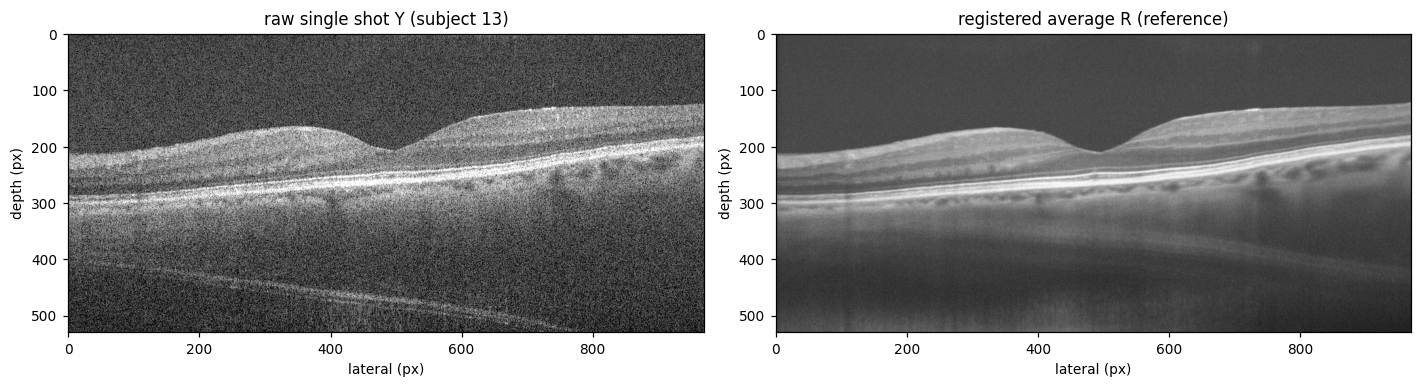

subject 13: Y (530, 970), R (530, 970)


In [5]:
Y0, R0 = load_pair(13)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, im, t in zip(ax, (Y0, R0), ("raw single shot Y (subject 13)",
                                   "registered average R (reference)")):
    a.imshow(im, vmin=0, vmax=255, aspect="auto")
    a.set_title(t); a.set_xlabel("lateral (px)"); a.set_ylabel("depth (px)")
fig.tight_layout()
plt.show()
print(f"subject 13: Y {Y0.shape}, R {R0.shape}")

## 3 · The joint solver

### 3.1 Working domain

OCT speckle is multiplicative, $Y=X\,n$; after $z=\log(1+y/255)/\log 2$ it becomes approximately
additive, which is the regime in which the quadratic data term and the $\ell_1$ regularisers are
meaningful. The step is invertible, $y=(\exp(z\log 2)-1)\cdot255$, so all metrics are computed on
the 8-bit linear scale. The dictionary was learned on 8-bit linear patches; OMP with a *fixed*
sparsity budget is scale-equivariant (scaling a patch scales correlations, coefficients and the
residual by the same factor and leaves the selected support unchanged), so no dictionary
re-normalisation is required.

### 3.2 Split-Bregman / ADMM blocks

Introduce $d=\nabla X-p$ and $v=\mathcal{E}(p)$ and their Bregman duals $b_d,b_v$. One outer
iteration is:

1. **$\alpha$-block** — extract all patches of $X$, run batched OMP on $D$ with budget $T$,
   reconstruct $\hat X_p=\text{avg}_{ij}(D\alpha_{ij})$.
2. **$X$-block** — exact FFT solve of
   $\big(1+\gamma_1|\nabla|^2+2\lambda C\big)\hat X
    =\widehat{Y-\gamma_1\,\mathrm{div}(d+p-b_d)+2\lambda C\,\hat X_p}$.
3. **$d$-block** — $d=\mathrm{shrink}(\nabla X-p+b_d,\ \alpha_1/\gamma_1)$.
4. **$p$-block** — FFT solve of $(\gamma_1 I+\gamma_2\mathcal{E}^{\top}\mathcal{E})p
   =\gamma_1(\nabla X-d+b_d)-\gamma_2\,\mathrm{div}_{\mathcal{E}}(v-b_v)$.
5. **$v$-block** — $v=\mathrm{shrink}(\mathcal{E}(p)+b_v,\ \alpha_0/\gamma_2)$ with weights (1,1,2).
6. **Bregman updates** — $b_d\mathrel{+}=\nabla X-p-d$, $b_v\mathrel{+}=\mathcal{E}(p)-v$.

The FFT diagonalisation is exact because patches wrap around and the grid stride $s$ divides the
image, so every pixel is covered by exactly $C=(8/s)^2$ patches and
$\sum_{ij}R_{ij}^{\top}R_{ij}=C I$.

### 3.3 Discrete operators (periodic, forward/backward differences, $h=1$)

In [6]:
def grad(u):
    '''Forward-difference gradient (d/dx, d/dy).'''
    return (np.roll(u, -1, axis=1) - u, np.roll(u, -1, axis=0) - u)


def div(g):
    '''Backward-difference divergence (= -grad^T, exact adjoint).'''
    g1, g2 = g
    return (g1 - np.roll(g1, 1, axis=1)) + (g2 - np.roll(g2, 1, axis=0))


def sym_grad(p):
    '''Symmetrised gradient E(p), returned as (e11, e22, e12) with e21 = e12.'''
    p1, p2 = p
    return (np.roll(p1, -1, axis=1) - p1,
            np.roll(p2, -1, axis=0) - p2,
            0.5 * (np.roll(p1, -1, axis=0) - p1 + np.roll(p2, -1, axis=1) - p2))


def div_sym(s):
    '''Divergence of a symmetric tensor field (backward differences, positive sign).'''
    s11, s22, s12 = s
    return ((s11 - np.roll(s11, 1, axis=1)) + (s12 - np.roll(s12, 1, axis=0)),
            (s12 - np.roll(s12, 1, axis=1)) + (s22 - np.roll(s22, 1, axis=0)))


def modulus(parts, weights=None):
    '''Pointwise isotropic (Frobenius) modulus; pass weights=(1,1,2) for a 2x2 tensor.'''
    weights = (1.0,) * len(parts) if weights is None else weights
    acc = np.zeros_like(parts[0])
    for q, w in zip(parts, weights):
        acc += w * q * q
    return np.sqrt(acc)


def shrink(z, thresh, weights=None):
    '''Isotropic soft-threshold: z * max(|z|-t, 0) / |z|, with 0/0 := 0.'''
    mag = modulus(z, weights)
    scale = np.zeros_like(mag)
    nz = mag > 0
    scale[nz] = np.maximum(mag[nz] - thresh, 0.0) / mag[nz]
    return tuple(scale * q for q in z)


def fft_symbols(shape):
    '''Fourier symbols of the forward differences and of the Laplacian.'''
    m, n = shape
    kx = 2 * np.pi * np.fft.fftfreq(n)
    ky = 2 * np.pi * np.fft.fftfreq(m)
    KX, KY = np.meshgrid(kx, ky)
    dx, dy = np.exp(1j * KX) - 1.0, np.exp(1j * KY) - 1.0
    return dict(dx=dx, dy=dy, lap=np.abs(dx) ** 2 + np.abs(dy) ** 2)

### 3.4 Patch extraction / aggregation and batched OMP

In [7]:
def patch_matrix(img, patch=8, stride=2):
    '''All wrap-around patch x patch patches on a stride grid -> (n_patches, patch^2), grid.'''
    H, W = img.shape
    assert H % stride == 0 and W % stride == 0, "stride must divide the image size"
    r0 = np.arange(0, H, stride)
    c0 = np.arange(0, W, stride)
    rows = (r0[:, None] + np.arange(patch)[None, :]) % H
    cols = (c0[:, None] + np.arange(patch)[None, :]) % W
    win = img[rows[:, None, :, None], cols[None, :, None, :]]
    return win.reshape(r0.size * c0.size, patch * patch), (r0.size, c0.size)


def patch_back(P, grid, patch=8, stride=2):
    '''Adjoint of patch_matrix / C: average every patch back onto the image grid.'''
    h, w = grid
    P = np.asarray(P).reshape(h, w, patch, patch)
    H, W = h * stride, w * stride
    acc = np.zeros((H, W))
    for dy in range(patch):
        r, q = dy % stride, dy // stride
        for dx in range(patch):
            c, u = dx % stride, dx // stride
            acc[r::stride, c::stride] += np.roll(np.roll(P[:, :, dy, dx], q, 0), u, 1)
    return acc / ((patch / stride) ** 2)


# self-test: extraction followed by aggregation is the identity
_z = np.random.default_rng(0).random((64, 80))
_P, _g = patch_matrix(_z, 8, 2)
assert np.abs(patch_back(_P, _g, 8, 2) - _z).max() < 1e-12
print("patch round-trip: exact (max error < 1e-12);",
      "n_patches for a 530x970 scan =", patch_matrix(np.zeros((530, 970)))[0].shape[0])

patch round-trip: exact (max error < 1e-12); n_patches for a 530x970 scan = 128525


In [8]:
def omp(D, Y, n_nonzero=1, tol=None, batch=16384):
    '''Batched orthogonal matching pursuit.

    Solves, for every column of Y, min ||y - D a||_2 s.t. ||a||_0 <= n_nonzero
    (optionally stopping earlier when the residual energy drops below `tol`).
    Returns (coefficients (N, T), support indices (N, T), -1 padded).
    '''
    n, K = D.shape
    N = Y.shape[1]
    G = D.T @ D
    vals = np.zeros((N, n_nonzero), np.float32)
    sup = np.full((N, n_nonzero), -1, np.int32)
    for start in range(0, N, batch):
        stop = min(start + batch, N)
        Yb = Y[:, start:stop]
        B = stop - start
        S = np.full((B, n_nonzero), -1, np.int32)
        A = np.zeros((B, n_nonzero), np.float32)
        r = Yb.copy()
        active = np.ones(B, bool)
        for t in range(n_nonzero):
            ia = np.flatnonzero(active)
            if ia.size == 0:
                break
            corr = np.abs(r[:, ia].T @ D)
            for j in range(t):                      # forbid already selected atoms
                col = S[ia, j]
                good = col >= 0
                corr[np.flatnonzero(good), col[good]] = -1.0
            S[ia, t] = corr.argmax(1)
            idx = S[ia, :t + 1]
            Gs = G[idx[:, :, None], idx[:, None, :]] + 1e-9 * np.eye(t + 1)
            Dsel = D.T[idx]
            b = np.einsum("bmn,bn->bm", Dsel, Yb[:, ia].T)
            a = np.linalg.solve(Gs, b[..., None])[..., 0]
            A[ia, :t + 1] = a
            r[:, ia] = Yb[:, ia] - np.einsum("bm,bmn->bn", a, Dsel).T
            if tol is not None:
                active[ia] = np.einsum("ij,ij->j", r[:, ia], r[:, ia]) > tol
        vals[start:stop] = A
        sup[start:stop] = S
    return vals, sup


t0 = time.perf_counter()
_P, _g = patch_matrix(np.log1p(Y0 / 255) / LOG2, 8, 2)
_v, _s = omp(D, _P.T, n_nonzero=1)
print(f"OMP smoke test: {_P.shape[0]:,} patches, 1 atom, {time.perf_counter()-t0:.2f} s")

OMP smoke test: 128,525 patches, 1 atom, 0.38 s


### 3.5 `JointKSVDTGV` — the alternating solver

In [9]:
class JointKSVDTGV:
    '''Early-stage joint K-SVD + TGV^2 denoising by alternating minimisation.

    The five blocks of section 3.2 are solved per outer iteration; the model energy
    (data + TGV + dictionary representation + L0) and optional reference metrics are
    recorded for every iteration.
    '''

    def __init__(self, dictionary: np.ndarray, cfg: JointConfig = CFG_DEFAULT, verbose=True):
        self.D = np.asarray(dictionary, np.float64)
        self.cfg = cfg
        self.verbose = verbose

    # -- working-domain transforms -------------------------------------------------
    @staticmethod
    def to_work(y):
        return np.log1p(np.clip(np.asarray(y, np.float64), 0.0, 255.0) / 255.0) / LOG2

    @staticmethod
    def from_work(z):
        return np.clip(np.expm1(np.clip(z, 0.0, 1.0) * LOG2), 0.0, 1.0) * 255.0

    # -- one patch-coding block ----------------------------------------------------
    def _code(self, X):
        c = self.cfg
        P, grid = patch_matrix(X, c.patch, c.stride)
        vals, sup = omp(self.D, P.T, n_nonzero=c.sparsity)
        est = np.einsum("bm,bmn->bn", vals, self.D.T[np.clip(sup, 0, self.D.shape[1] - 1)])
        return est, sup, grid

    def solve(self, Y_raw, reference=None):
        '''Run the joint solver on one raw B-scan.

        Returns (X_linear float64 on [0,255], history dict).
        '''
        c = self.cfg
        D = self.D
        p, s = c.patch, c.stride
        Z = self.to_work(Y_raw)
        H, W = Z.shape
        X = Z.copy()

        # split / dual variables of the TGV block
        d = (np.zeros((H, W)), np.zeros((H, W)))
        pv = (np.zeros((H, W)), np.zeros((H, W)))
        v = tuple(np.zeros((H, W)) for _ in range(3))
        bd = (np.zeros((H, W)), np.zeros((H, W)))
        bv = tuple(np.zeros((H, W)) for _ in range(3))

        # constant FFT symbols
        sym = fft_symbols((H, W))
        dx, dy = sym["dx"], sym["dy"]
        # (gamma1 I + gamma2 E^T E) for the p-block
        b11 = c.gamma1 + c.gamma2 * (np.abs(dx) ** 2 + 0.5 * np.abs(dy) ** 2)
        b22 = c.gamma1 + c.gamma2 * (0.5 * np.abs(dx) ** 2 + np.abs(dy) ** 2)
        b12 = 0.5 * c.gamma2 * dx * np.conj(dy)
        detB = b11 * b22 - np.abs(b12) ** 2
        C = (p / s) ** 2
        denX = 1.0 + c.gamma1 * sym["lap"] + 2.0 * c.lam * C

        hist = {"energy": [], "augmented": [], "rel_x": [], "fidelity": [], "tgv1": [],
                "tgv0": [], "patch": [], "l0": [], "psnr": [], "ssim": [], "epi": [],
                "time_s": [], "atoms": []}
        t_start = time.perf_counter()

        for k in range(1, c.max_iters + 1):
            t_iter = time.perf_counter()

            # ---- (1) alpha-block: sparse coding of the current X ------------------
            est, sup, grid = self._code(X)
            n_atoms = int((sup >= 0).sum())
            Xp = patch_back(est, grid, p, s)

            # ---- (2) X-block: exact FFT solve ------------------------------------
            X_prev = X
            rhs = (Z
                   - c.gamma1 * div((d[0] + pv[0] - bd[0], d[1] + pv[1] - bd[1]))
                   + 2.0 * c.lam * C * Xp)
            X = np.real(np.fft.ifft2(np.fft.fft2(rhs) / denX))
            rel_x = float(np.linalg.norm(X - X_prev) / max(np.linalg.norm(X), 1e-12))

            # ---- (3) d-block ------------------------------------------------------
            ux, uy = grad(X)
            d = shrink((ux - pv[0] + bd[0], uy - pv[1] + bd[1]), c.alpha1 / c.gamma1)

            # ---- (4) p-block ------------------------------------------------------
            d1, d2 = div_sym((v[0] - bv[0], v[1] - bv[1], v[2] - bv[2]))
            R1 = c.gamma1 * (ux - d[0] + bd[0]) - c.gamma2 * d1
            R2 = c.gamma1 * (uy - d[1] + bd[1]) - c.gamma2 * d2
            H1, H2 = np.fft.fft2(R1), np.fft.fft2(R2)
            pv = (np.real(np.fft.ifft2((b22 * H1 - b12 * H2) / detB)),
                  np.real(np.fft.ifft2((-np.conj(b12) * H1 + b11 * H2) / detB)))

            # ---- (5) v-block ------------------------------------------------------
            e11, e22, e12 = sym_grad(pv)
            v = shrink((e11 + bv[0], e22 + bv[1], e12 + bv[2]),
                       c.alpha0 / c.gamma2, weights=(1, 1, 2))

            # ---- (6) Bregman dual updates ----------------------------------------
            # split-constraint residuals *before* the dual update (used for the
            # augmented-energy diagnostic below)
            rd1 = d[0] - ux + pv[0] - bd[0]
            rd2 = d[1] - uy + pv[1] - bd[1]
            rv1 = v[0] - e11 - bv[0]
            rv2 = v[1] - e22 - bv[1]
            rv3 = v[2] - e12 - bv[2]
            penalty = 0.5 * c.gamma1 * float(np.sum(rd1 ** 2 + rd2 ** 2)) \
                + 0.5 * c.gamma2 * float(np.sum(rv1 ** 2 + rv2 ** 2 + 2.0 * rv3 ** 2))

            bd = (bd[0] + (ux - pv[0] - d[0]), bd[1] + (uy - pv[1] - d[1]))
            bv = (bv[0] + (e11 - v[0]), bv[1] + (e22 - v[1]), bv[2] + (e12 - v[2]))

            # ---- diagnostics: model energy at the new X ---------------------------
            Pn, _ = patch_matrix(X, p, s)
            patch_res = float(np.sum((est - Pn) ** 2))
            fid = 0.5 * float(np.sum((Z - X) ** 2))
            tv1 = c.alpha1 * float(np.sum(modulus(d)))
            tv0 = c.alpha0 * float(np.sum(modulus(v, (1, 1, 2))))
            l0 = c.lam * c.mu * n_atoms
            energy = fid + tv1 + tv0 + c.lam * patch_res + l0
            augmented = energy + penalty

            hist["energy"].append(energy)
            hist["augmented"].append(augmented)
            hist["rel_x"].append(rel_x)
            hist["fidelity"].append(fid)
            hist["tgv1"].append(tv1)
            hist["tgv0"].append(tv0)
            hist["patch"].append(c.lam * patch_res)
            hist["l0"].append(l0)
            hist["atoms"].append(n_atoms / max(1, sup.shape[0]))
            hist["time_s"].append(time.perf_counter() - t_iter)

            if reference is not None:
                Xl = self.from_work(X)
                hist["psnr"].append(psnr(reference, Xl))
                hist["ssim"].append(float(ssim_map(reference, Xl).mean()))
                hist["epi"].append(epi(reference, Xl))

            if self.verbose:
                tail = (f" | PSNR {hist['psnr'][-1]:6.2f} dB  SSIM {hist['ssim'][-1]:.3f}"
                        if reference is not None else "")
                print(f"  iter {k:02d}  E={energy:.4e}  fid={fid:.3e}  tv1={tv1:.3e}  "
                      f"tv0={tv0:.3e}  patch={c.lam*patch_res:.3e}  "
                      f"dX={rel_x:.2e}{tail}  [{hist['time_s'][-1]:.2f}s]", flush=True)

            if k >= 3 and rel_x < c.tol:
                if self.verbose:
                    print(f"  converged: relative change of X {rel_x:.2e} < {c.tol:.0e}")
                break

        hist["n_iters"] = len(hist["energy"])
        hist["time_total_s"] = time.perf_counter() - t_start
        hist["X_work"] = X
        hist["config"] = asdict(c)
        return self.from_work(X), hist

## 4 · Evaluation metrics

All metrics are computed on the 8-bit linear scale against the averaged reference $R$.

* **PSNR** — global, and **ROI PSNR** restricted to the retinal tissue mask
  (`smoothed R > Otsu`), where the signal actually is.
* **SSIM** — Wang et al. (2004), 11×11 Gaussian window, $\sigma=1.5$, `data_range=255`;
  **edge-band SSIM** averages the SSIM map inside the dilated band of the strongest reference
  edges (top 3 % Sobel magnitude, dilated by 2 px, intersected with tissue).
* **EPI** — Pearson correlation of the Sobel gradient magnitudes of $R$ and the estimate.
* **10–90 % boundary rise distance** — for the six strongest horizontal layer boundaries of $R$,
  each A-scan segment of ±7 px is normalised between its upper/lower plateau medians and the
  distance between the 10 % and 90 % crossings is measured with sub-pixel interpolation, then
  averaged over boundaries and columns. It is a direct measure of edge softening: a larger value
  means a softer boundary. **On the raw scan the value is noise-inflated** (noise produces steep
  local crossings), so raw is reported for context only; the meaningful comparison is between
  denoised outputs and the reference's own width.

In [10]:
def psnr(ref, img, peak=PEAK, mask=None):
    d = (np.asarray(ref, float) - np.asarray(img, float)) ** 2
    m = float(d.mean()) if mask is None else float(d[mask].mean())
    return float("inf") if m <= 0 else float(10 * np.log10(peak ** 2 / m))


def ssim_map(ref, img):
    '''Full SSIM map (Wang et al.: Gaussian 11x11, sigma 1.5, data_range 255).'''
    return structural_similarity(np.asarray(ref, float), np.asarray(img, float),
                                 data_range=PEAK, gaussian_weights=True, sigma=1.5,
                                 use_sample_covariance=False, full=True)[1]


def epi(ref, img):
    '''Sobel edge-preservation index: correlation of the two gradient-magnitude maps.'''
    def sob(x):
        x = np.asarray(x, float)
        return np.hypot(ndimage.sobel(x, axis=1, mode="reflect"),
                        ndimage.sobel(x, axis=0, mode="reflect"))
    a, b = sob(ref), sob(img)
    a, b = a - a.mean(), b - b.mean()
    den = np.sqrt((a * a).sum() * (b * b).sum())
    return float((a * b).sum() / den) if den > 0 else 0.0


def roi_masks(ref):
    '''Tissue ROI and reference edge band (both derived from the reference only).'''
    ref = np.asarray(ref, float)
    mu = ndimage.gaussian_filter(ref, 7.0, mode="reflect")
    thr = float(threshold_otsu(mu))
    tissue = mu > thr
    g = np.hypot(ndimage.sobel(mu, axis=1), ndimage.sobel(mu, axis=0))
    edge_thr = float(np.percentile(g[tissue], 97))
    band = ndimage.binary_dilation(g >= edge_thr, iterations=2) & tissue
    return {"tissue": tissue, "band": band}


def boundary_rows(ref, n_boundaries=6, min_sep=12, halfwin=7):
    '''Rows of the strongest horizontal layer boundaries, from the reference mean A-scan.'''
    H = ref.shape[0]
    prof = ndimage.gaussian_filter1d(np.asarray(ref, float).mean(axis=1), 2.0)
    g = np.abs(np.gradient(prof))
    lo, hi = int(0.15 * H), int(0.90 * H)
    order = np.argsort(g[lo:hi])[::-1] + lo
    picked = []
    for y in order:
        if all(abs(int(y) - q) >= min_sep for q in picked):
            picked.append(int(y))
        if len(picked) >= n_boundaries:
            break
    return sorted(picked)


def rise_distance(ref, img, rows=None, halfwin=7, min_contrast=6.0):
    '''Mean 10-90 % intensity rise distance (px) across the reference layer boundaries.

    For every boundary row and A-scan the profile is oriented, normalised between its plateau
    medians and the 10 % / 90 % crossings are linearly interpolated. Segments that do not span
    both levels are skipped. Returns (mean, s.d., number of measurements).
    '''
    ref = np.asarray(ref, float)
    img = np.asarray(img, float)
    H, W = ref.shape
    rows = boundary_rows(ref) if rows is None else rows
    widths = []
    for y0 in rows:
        seg = img[max(0, y0 - halfwin):min(H, y0 + halfwin + 1), int(0.15 * W):int(0.85 * W)]
        if seg.shape[0] < 5:
            continue
        lo_lvl, hi_lvl = np.median(seg[:3], axis=0), np.median(seg[-3:], axis=0)
        contrast = hi_lvl - lo_lvl
        keep = np.abs(contrast) > min_contrast
        if not keep.any():
            continue
        s = np.clip((seg - lo_lvl) / np.where(np.abs(contrast) < 1e-9, 1e-9, contrast),
                    -0.1, 1.1)
        ys = np.arange(seg.shape[0])
        yy = np.arange(0.0, seg.shape[0] - 1.0, 0.02)
        for c in np.nonzero(keep)[0]:
            prof = np.interp(yy, ys, s[:, c])
            if prof[0] > 0.05 or prof[-1] < 0.95:      # must actually span the edge
                continue
            i10, i90 = np.argmax(prof >= 0.10), np.argmax(prof >= 0.90)
            if i90 > i10:
                widths.append(yy[i90] - yy[i10])
    if not widths:
        return float("nan"), float("nan"), 0
    return float(np.mean(widths)), float(np.std(widths)), len(widths)


def evaluate(ref, img, masks=None, rows=None):
    '''All metrics for one estimate against the reference.'''
    masks = roi_masks(ref) if masks is None else masks
    rows = boundary_rows(ref) if rows is None else rows
    smap = ssim_map(ref, img)
    rise, rise_sd, n = rise_distance(ref, img, rows)
    return {
        "PSNR": psnr(ref, img),
        "ROI_PSNR": psnr(ref, img, mask=masks["tissue"]),
        "SSIM": float(smap.mean()),
        "EdgeSSIM": float(smap[masks["band"]].mean()),
        "EPI": epi(ref, img),
        "Rise_px": rise,
        "Rise_sd": rise_sd,
        "n_rise": n,
    }


# --- sanity check: a perfect estimate and the boundary summary ----------------------
_mk = roi_masks(R0)
_rows = boundary_rows(R0)
_ref_rise, _ref_sd, _ = rise_distance(R0, R0, _rows)
print("subject 13 reference: boundaries", _rows,
      f"| tissue {_mk['tissue'].mean()*100:.1f}% of pixels, edge band {_mk['band'].mean()*100:.1f}%")
print(f"reference's own 10-90% rise distance: {_ref_rise:.2f} px "
      f"(s.d. {_ref_sd:.2f}; this is the sharpness ceiling set by the averaged reference)")
print("raw metrics:", {k: (round(v, 3) if isinstance(v, float) else v)
                       for k, v in evaluate(R0, Y0, _mk, _rows).items()})

subject 13 reference: boundaries [131, 169, 196, 290, 303, 315] | tissue 26.2% of pixels, edge band 1.3%
reference's own 10-90% rise distance: 5.91 px (s.d. 3.43; this is the sharpness ceiling set by the averaged reference)
raw metrics: {'PSNR': 17.367, 'ROI_PSNR': 16.643, 'SSIM': 0.08, 'EdgeSSIM': 0.339, 'EPI': 0.146, 'Rise_px': 3.486, 'Rise_sd': 3.554, 'n_rise': 1575}


## 5 · Baselines

1. **Standalone K-SVD (Zhang et al. 2022)** — the repository's implementation: GLCM/Laplacian noise
   estimate, OMP with an error limit $\epsilon=1.15\sigma\sqrt{64}$ capped at 12 atoms, and the
   closed-form fidelity blend of Eq. (3) with $\lambda=30/\sigma$. Re-implemented here (the shared
   `Comparison/methods.py` module is not imported, so this notebook stays self-contained);
   it reproduces the repository's published per-image value for subject 13 (23.75 dB).
2. **Standalone TGV$^2$ (Duan et al. 2016)** — the repository's split-Bregman solver in `TGV_denoising/src`,
   loaded unmodified, with the tuned parameters $lpha_0=lpha_1=0.1$, $eta=0.1$,
   $\lambda_{1,2,3}=2$.
3. **Late-stage pixel-space blending** — $X_{\text{blend}}=wX_{\text{KSVD}}+(1-w)X_{\text{TGV}}$,
   the previous fusion approach. The weight is selected on the validation subjects 13–14. The
   tuned optimum turns out to be $w=0$ — the K-SVD estimate is below TGV on those scans, so any
   positive weight costs PSNR and late fusion collapses to TGV alone. The **equal-weight** blend
   $w=0.5$ is therefore reported as well, as the neutral, non-degenerate late-fusion baseline.

In [11]:
# ---- standalone K-SVD (faithful port of Comparison/methods.ksvd_denoise) -----------
_N_KERNEL = np.array([[1., -2., 1.], [-2., 4., -2.], [1., -2., 1.]])


def estimate_noise_sigma(block):
    r = convolve2d(np.asarray(block, float), _N_KERNEL, mode="valid")
    h, w = r.shape
    return float(np.sqrt(np.pi / 2) * np.abs(r).sum() / (6.0 * (w - 2) * (h - 2)))


def glcm_entropy(block, levels=32):
    q = np.clip((np.asarray(block, float) / PEAK * levels).astype(np.int32), 0, levels - 1)
    g = graycomatrix(q, distances=[1], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                     levels=levels, symmetric=True, normed=True).astype(float)
    p = g + 1e-12
    return float(-(p * np.log2(p)).sum() / g.shape[3])


def weak_texture_sigma(img, block=64, min_std=2.0):
    '''Noise intensity from the weakest-texture 64x64 tile (minimum GLCM entropy).'''
    best = None
    H, W = img.shape
    for y in range(0, H - block + 1, block):
        for x in range(0, W - block + 1, block):
            tile = np.asarray(img[y:y + block, x:x + block], float)
            if tile.std() < min_std:
                continue
            e = glcm_entropy(tile)
            if best is None or e < best[0]:
                best = (e, tile)
    return estimate_noise_sigma(best[1])


def ksvd_denoise(img, D, omp_C=1.15, lambda_scale=30.0, sigma=None, patch=8, max_atoms=12):
    '''K-SVD + OMP + Eq. (3) reconstruction on the 8-bit scale.'''
    img = np.asarray(img, float)
    sigma = weak_texture_sigma(img) if sigma is None else sigma
    pad = patch // 2
    padded = np.pad(img, pad, mode="reflect")
    win = np.lib.stride_tricks.sliding_window_view(padded, (patch, patch))
    h, w = win.shape[:2]
    P = win.reshape(h * w, patch * patch)
    tol = (omp_C * sigma * np.sqrt(patch * patch)) ** 2
    vals, sup = omp(D, P.T, n_nonzero=max_atoms, tol=tol)
    est = np.einsum("bm,bmn->bn", vals, D.T[np.clip(sup, 0, D.shape[1] - 1)])
    acc = np.zeros((h + patch - 1, w + patch - 1))
    cnt = np.zeros_like(acc)
    Ps = est.reshape(h, w, patch, patch)
    for dy in range(patch):
        for dx in range(patch):
            acc[dy:dy + h, dx:dx + w] += Ps[:, :, dy, dx]
            cnt[dy:dy + h, dx:dx + w] += 1.0
    lam = lambda_scale / max(sigma, 1e-8)
    out = ((lam * padded + acc) / (lam + cnt))[pad:-pad, pad:-pad]
    return np.clip(out, 0, PEAK), sigma


# ---- standalone TGV^2: load the repository solver from TGV_denoising/src ---------------------
def load_tgv_solver():
    '''Import TGV_denoising/src as a uniquely named package and return its tgv module.'''
    name = "oct_tgv_reference"
    if name not in sys.modules:
        pkg = REPO / "TGV_denoising" / "src"
        spec = importlib.util.spec_from_file_location(
            name, pkg / "__init__.py", submodule_search_locations=[str(pkg)])
        mod = importlib.util.module_from_spec(spec)
        sys.modules[name] = mod
        spec.loader.exec_module(mod)
    return importlib.import_module(name + ".tgv")


TGV = load_tgv_solver()


def tgv_denoise(img, alpha=0.1, beta=0.1, lam=2.0, max_iter=300, tol=1e-3):
    '''Duan et al. TGV^2 decomposition; the solver works on [0, 1].'''
    u, _, info = TGV.tgv_decompose(np.asarray(img, float) / PEAK,
                                   alpha0=alpha, alpha1=alpha, beta=beta,
                                   lam1=lam, lam2=lam, lam3=lam,
                                   max_iter=max_iter, tol=tol, return_info=True)
    return np.clip(u * PEAK, 0, PEAK), info


t0 = time.perf_counter()
X_ksvd_demo, sig_demo = ksvd_denoise(Y0, D)
t_ksvd = time.perf_counter() - t0
t0 = time.perf_counter()
X_tgv_demo, info_demo = tgv_denoise(Y0)
t_tgv = time.perf_counter() - t0
print(f"K-SVD: {t_ksvd:.1f} s, sigma_hat = {sig_demo:.2f}")
print(f"TGV  : {t_tgv:.1f} s, {info_demo['n_iter']} iterations")
print("demo PSNR  K-SVD %.2f dB | TGV %.2f dB" %
      (psnr(R0, X_ksvd_demo), psnr(R0, X_tgv_demo)))

K-SVD: 7.2 s, sigma_hat = 26.05
TGV  : 6.3 s, 15 iterations
demo PSNR  K-SVD 23.75 dB | TGV 25.42 dB


## 6 · Hyper-parameter selection on the validation subjects (13–14)

The dictionary is fixed; only $(\lambda,\alpha_1,\alpha_0)$ are free. Six configurations are
scored on subjects 13–14 with at most 25 iterations each; the configuration with the best mean
PSNR is frozen for the 17-subject benchmark. $\alpha_0$ is tied to $\alpha_1$ (ratio 0.5, the
balance used in the TGV reproduction), and the L0 budget is $T=1$ atom/patch: with this
dictionary the single-atom code is the noise-level solution, and larger budgets ($T\ge2$) were
measured to fit speckle and lose 1–2 dB.

In [12]:
VAL_SUBJECTS = (13, 14)
GRID = [(lam, a1) for lam in (0.10, 0.15, 0.25) for a1 in (0.05, 0.08)]

tune_rows = []
for lam, a1 in GRID:
    cfg = JointConfig(lam=lam, alpha1=a1, alpha0=0.5 * a1, max_iters=25, tol=1e-5)
    per_subject = []
    t0 = time.perf_counter()
    for s in VAL_SUBJECTS:
        Ys, Rs = load_pair(s)
        mk, rows = roi_masks(Rs), boundary_rows(Rs)
        Xs, _ = JointKSVDTGV(D, cfg, verbose=False).solve(Ys, Rs)
        per_subject.append(evaluate(Rs, Xs, mk, rows))
    dt = time.perf_counter() - t0
    tune_rows.append({
        "lambda": lam, "alpha1": a1, "alpha0": 0.5 * a1,
        "PSNR": np.mean([m["PSNR"] for m in per_subject]),
        "ROI_PSNR": np.mean([m["ROI_PSNR"] for m in per_subject]),
        "SSIM": np.mean([m["SSIM"] for m in per_subject]),
        "EdgeSSIM": np.mean([m["EdgeSSIM"] for m in per_subject]),
        "EPI": np.mean([m["EPI"] for m in per_subject]),
        "Rise_px": np.mean([m["Rise_px"] for m in per_subject]),
        "time_s": dt,
    })
    print(f"lam={lam:.2f} a1={a1:.2f} a0={0.5*a1:.3f} | PSNR {tune_rows[-1]['PSNR']:.2f} "
          f"SSIM {tune_rows[-1]['SSIM']:.3f} EPI {tune_rows[-1]['EPI']:.3f} "
          f"rise {tune_rows[-1]['Rise_px']:.2f} px | {dt:.0f}s", flush=True)

tuning_df = pd.DataFrame(tune_rows).sort_values("PSNR", ascending=False).reset_index(drop=True)
tuning_df.to_csv(OUT_DIR / "validation_grid.csv", index=False)
print()
print(tuning_df.round(3).to_string(index=False))
best = tuning_df.iloc[0]
CFG = JointConfig(lam=float(best["lambda"]), alpha1=float(best["alpha1"]),
                  alpha0=float(best["alpha0"]), max_iters=40, tol=1e-5)
print(f"\nselected and frozen: {asdict(CFG)}")

lam=0.10 a1=0.05 a0=0.025 | PSNR 26.47 SSIM 0.585 EPI 0.432 rise 6.63 px | 52s


lam=0.10 a1=0.08 a0=0.040 | PSNR 26.73 SSIM 0.633 EPI 0.502 rise 7.03 px | 56s


lam=0.15 a1=0.05 a0=0.025 | PSNR 26.59 SSIM 0.620 EPI 0.459 rise 7.10 px | 54s


lam=0.15 a1=0.08 a0=0.040 | PSNR 26.72 SSIM 0.649 EPI 0.515 rise 7.47 px | 54s


lam=0.25 a1=0.05 a0=0.025 | PSNR 26.47 SSIM 0.646 EPI 0.483 rise 7.68 px | 54s


lam=0.25 a1=0.08 a0=0.040 | PSNR 26.51 SSIM 0.659 EPI 0.518 rise 7.96 px | 55s



 lambda  alpha1  alpha0   PSNR  ROI_PSNR  SSIM  EdgeSSIM   EPI  Rise_px  time_s
   0.10    0.08   0.040 26.734    24.173 0.633     0.622 0.502    7.027  55.622
   0.15    0.08   0.040 26.724    23.884 0.649     0.591 0.515    7.475  54.155
   0.15    0.05   0.025 26.585    23.829 0.620     0.594 0.459    7.105  54.333
   0.25    0.08   0.040 26.512    23.315 0.659     0.556 0.518    7.964  54.698
   0.10    0.05   0.025 26.469    24.044 0.585     0.624 0.432    6.633  52.205
   0.25    0.05   0.025 26.467    23.310 0.646     0.559 0.483    7.679  54.205

selected and frozen: {'lam': 0.1, 'alpha1': 0.08, 'alpha0': 0.04, 'gamma1': 2.0, 'gamma2': 2.0, 'mu': 0.001, 'sparsity': 1, 'patch': 8, 'stride': 2, 'max_iters': 40, 'tol': 1e-05}


In [13]:
# ---- late-stage blend weights, selected on the same validation subjects -----------
# Both components are computed once per subject; the sweep then only re-blends them.
w_grid = np.round(np.arange(0.0, 0.61, 0.1), 2)
blend_scores = {float(w): [] for w in w_grid}
ksvd_minus_tgv = []
for s in VAL_SUBJECTS:
    Ys, Rs = load_pair(s)
    Xk, _ = ksvd_denoise(Ys, D)
    Xt, _ = tgv_denoise(Ys)
    ksvd_minus_tgv.append(psnr(Rs, Xk) - psnr(Rs, Xt))
    for w in w_grid:
        blend_scores[float(w)].append(psnr(Rs, np.clip(w * Xk + (1 - w) * Xt, 0, PEAK)))
blend_scores = {k: float(np.mean(v)) for k, v in blend_scores.items()}
W_BLEND = max(blend_scores, key=blend_scores.get)   # validation-tuned share of K-SVD
W_BLEND_EQ = 0.5                                    # equal-weight late fusion (naive baseline)
print("blend weight sweep (mean PSNR dB):",
      {k: round(v, 3) for k, v in blend_scores.items()})
print(f"validation-tuned blend: w* = {W_BLEND:.2f} (K-SVD share)")
print(f"K-SVD minus TGV on the validation scans: {np.mean(ksvd_minus_tgv):+.2f} dB")
if W_BLEND == 0.0:
    print("note: the tuned optimum puts zero weight on the K-SVD output, so late fusion")
    print("      collapses to TGV alone; the equal-weight blend is reported as the")
    print("      non-degenerate late-fusion baseline.")
print(f"equal-weight late fusion reported as a second baseline: w = {W_BLEND_EQ:.1f}")

blend weight sweep (mean PSNR dB): {0.0: 26.743, 0.1: 26.739, 0.2: 26.71, 0.3: 26.656, 0.4: 26.581, 0.5: 26.483, 0.6: 26.367}
validation-tuned blend: w* = 0.00 (K-SVD share)
K-SVD minus TGV on the validation scans: -1.00 dB
note: the tuned optimum puts zero weight on the K-SVD output, so late fusion
      collapses to TGV alone; the equal-weight blend is reported as the
      non-degenerate late-fusion baseline.
equal-weight late fusion reported as a second baseline: w = 0.5


## 7 · Featured run on subject 13 — convergence

The frozen configuration is run for up to 40 outer iterations on subject 13 with the reference
metrics logged every iteration. The stopping rule is the relative change of the iterate,
$\|X_k-X_{k-1}\|/\|X_k\|<10^{-5}$ (the same rule the repository's TGV solver uses), because the
model objective is not guaranteed to decrease monotonically — the $lpha$-block is a non-convex
L0 step and the split penalty is excluded from the printed energy. The printout reports the energy
split into data, TGV and dictionary terms so the balance between the three blocks is visible.

In [14]:
Y13, R13 = load_pair(13)
MK13, ROWS13 = roi_masks(R13), boundary_rows(R13)

t0 = time.perf_counter()
X_joint13, HIST13 = JointKSVDTGV(D, CFG, verbose=True).solve(Y13, R13)
print(f"\njoint solve: {HIST13['n_iters']} iterations, {time.perf_counter()-t0:.1f} s")
print("final metrics:", {k: round(v, 3) if isinstance(v, float) else v
                          for k, v in evaluate(R13, X_joint13, MK13, ROWS13).items()})

  iter 01  E=4.8200e+03  fid=3.964e+03  tv1=4.427e+01  tv0=2.224e-01  patch=7.986e+02  dX=2.73e-01 | PSNR  25.51 dB  SSIM 0.587  [1.06s]


  iter 02  E=4.7580e+03  fid=4.210e+03  tv1=5.335e+01  tv0=2.100e+01  patch=4.611e+02  dX=1.48e-02 | PSNR  25.74 dB  SSIM 0.612  [1.00s]


  iter 03  E=5.0011e+03  fid=4.449e+03  tv1=1.115e+02  tv0=5.739e+01  patch=3.702e+02  dX=1.01e-02 | PSNR  25.88 dB  SSIM 0.631  [1.00s]


  iter 04  E=5.0788e+03  fid=4.468e+03  tv1=1.574e+02  tv0=9.054e+01  patch=3.499e+02  dX=5.40e-03 | PSNR  25.90 dB  SSIM 0.633  [1.00s]


  iter 05  E=5.0768e+03  fid=4.418e+03  tv1=1.733e+02  tv0=1.190e+02  patch=3.533e+02  dX=3.88e-03 | PSNR  25.88 dB  SSIM 0.629  [0.98s]


  iter 06  E=5.0795e+03  fid=4.392e+03  tv1=1.758e+02  tv0=1.421e+02  patch=3.567e+02  dX=2.47e-03 | PSNR  25.87 dB  SSIM 0.626  [0.97s]


... (30 outputs left out)

  iter 37  E=5.0907e+03  fid=4.369e+03  tv1=1.419e+02  tv0=2.061e+02  patch=3.605e+02  dX=1.15e-05 | PSNR  25.83 dB  SSIM 0.621  [1.04s]


  iter 38  E=5.0907e+03  fid=4.369e+03  tv1=1.419e+02  tv0=2.062e+02  patch=3.605e+02  dX=1.06e-05 | PSNR  25.83 dB  SSIM 0.621  [1.00s]


  iter 39  E=5.0908e+03  fid=4.369e+03  tv1=1.418e+02  tv0=2.062e+02  patch=3.605e+02  dX=9.82e-06 | PSNR  25.83 dB  SSIM 0.621  [1.02s]


  converged: relative change of X 9.82e-06 < 1e-05

joint solve: 39 iterations, 42.6 s
final metrics: {'PSNR': 25.826, 'ROI_PSNR': 23.825, 'SSIM': 0.621, 'EdgeSSIM': 0.617, 'EPI': 0.447, 'Rise_px': 6.581, 'Rise_sd': 3.025, 'n_rise': 2121}


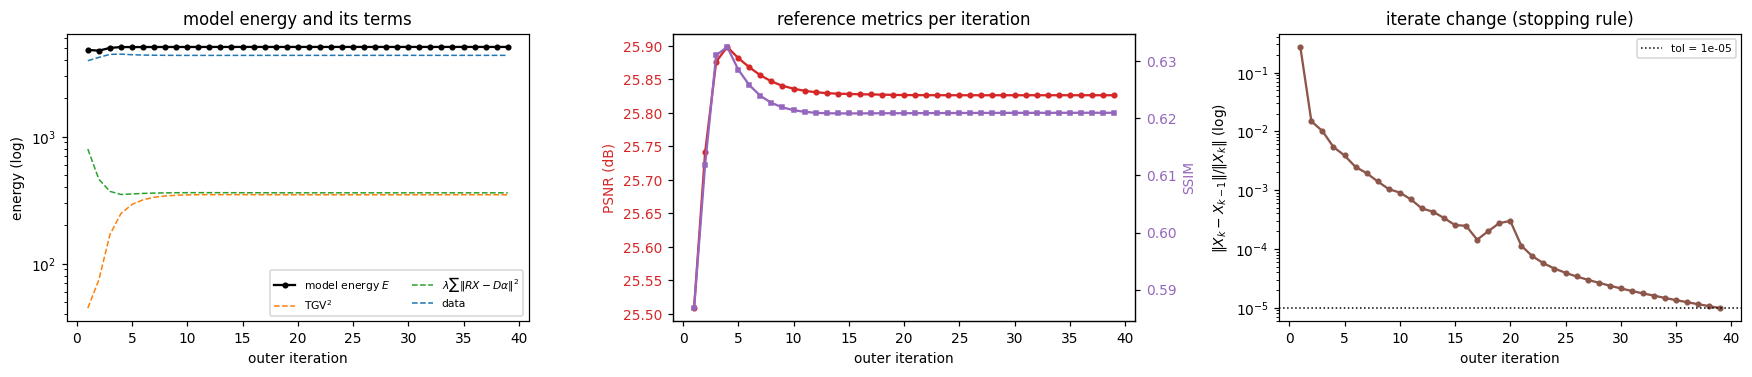

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
it = np.arange(1, HIST13["n_iters"] + 1)
ax[0].semilogy(it, HIST13["energy"], "k-o", ms=3, label="model energy $E$")
ax[0].semilogy(it, np.add(HIST13["tgv1"], HIST13["tgv0"]), "C1--", lw=1, label="TGV$^2$")
ax[0].semilogy(it, HIST13["patch"], "C2--", lw=1, label="$\\lambda\\sum\\|R X-D\\alpha\\|^2$")
ax[0].semilogy(it, HIST13["fidelity"], "C0--", lw=1, label="data")
ax[0].set_xlabel("outer iteration"); ax[0].set_ylabel("energy (log)")
ax[0].set_title("model energy and its terms"); ax[0].legend(fontsize=7, ncol=2)

ax1 = ax[1]
ax1.plot(it, HIST13["psnr"], "C3-o", ms=3)
ax1.set_xlabel("outer iteration"); ax1.set_ylabel("PSNR (dB)", color="C3")
ax1.tick_params(axis="y", labelcolor="C3")
ax1b = ax1.twinx()
ax1b.plot(it, HIST13["ssim"], "C4-s", ms=3)
ax1b.set_ylabel("SSIM", color="C4"); ax1b.tick_params(axis="y", labelcolor="C4")
ax1.set_title("reference metrics per iteration")

ax[2].semilogy(it, HIST13["rel_x"], "C5-o", ms=3)
ax[2].axhline(CFG.tol, color="k", ls=":", lw=1, label=f"tol = {CFG.tol:.0e}")
ax[2].set_xlabel("outer iteration"); ax[2].set_ylabel("$\\|X_k-X_{k-1}\\|/\\|X_k\\|$ (log)")
ax[2].set_title("iterate change (stopping rule)"); ax[2].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig01_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

## 8 · Benchmark on all 17 paired B-scans

Each method is scored per subject; the table reports mean ± s.d. across the 17 scans. Timings are
wall-clock on the CPU used for this run.

In [16]:
METHOD_ORDER = ["Raw input", "K-SVD", "TGV$^2$", f"Late blend (w={W_BLEND:.1f})", "Joint (new)"]
records = []
STORE = {}

for s in sorted(CASES):
    Ys, Rs = load_pair(s)
    mk, rows = roi_masks(Rs), boundary_rows(Rs)
    row = {"subject": s}

    row.update({f"raw_{k}": v for k, v in evaluate(Rs, Ys, mk, rows).items()})

    t0 = time.perf_counter(); Xk, sig = ksvd_denoise(Ys, D); tk = time.perf_counter() - t0
    row.update({f"ksvd_{k}": v for k, v in evaluate(Rs, Xk, mk, rows).items()})
    row["ksvd_time_s"] = tk; row["sigma_hat"] = sig

    t0 = time.perf_counter(); Xt, tinfo = tgv_denoise(Ys); tt = time.perf_counter() - t0
    row.update({f"tgv_{k}": v for k, v in evaluate(Rs, Xt, mk, rows).items()})
    row["tgv_time_s"] = tt; row["tgv_iters"] = tinfo["n_iter"]

    Xb = np.clip(W_BLEND * Xk + (1 - W_BLEND) * Xt, 0, PEAK)
    row.update({f"blend_{k}": v for k, v in evaluate(Rs, Xb, mk, rows).items()})

    Xbe = np.clip(W_BLEND_EQ * Xk + (1 - W_BLEND_EQ) * Xt, 0, PEAK)
    row.update({f"blendeq_{k}": v for k, v in evaluate(Rs, Xbe, mk, rows).items()})

    t0 = time.perf_counter(); Xj, hj = JointKSVDTGV(D, CFG, verbose=False).solve(Ys, Rs)
    tj = time.perf_counter() - t0
    row.update({f"joint_{k}": v for k, v in evaluate(Rs, Xj, mk, rows).items()})
    row["joint_time_s"] = tj; row["joint_iters"] = hj["n_iters"]

    records.append(row)
    if s == 13:
        STORE.update(Y=Ys, R=Rs, ksvd=Xk, tgv=Xt, blend=Xb, blend_eq=Xbe, joint=Xj, hist=hj)
    print(f"subject {s:2d}: raw {row['raw_PSNR']:.2f} | ksvd {row['ksvd_PSNR']:.2f} | "
          f"tgv {row['tgv_PSNR']:.2f} | blend {row['blend_PSNR']:.2f} | "
          f"joint {row['joint_PSNR']:.2f} dB  ({hj['n_iters']} it, {tj:.0f}s)", flush=True)

bench = pd.DataFrame(records)
bench.to_csv(OUT_DIR / "benchmark_per_image.csv", index=False)
print("\nper-image table written to", OUT_DIR / "benchmark_per_image.csv")

subject  1: raw 17.28 | ksvd 27.47 | tgv 27.21 | blend 27.21 | joint 27.90 dB  (40 it, 45s)


subject  2: raw 17.90 | ksvd 26.36 | tgv 28.46 | blend 28.46 | joint 28.20 dB  (40 it, 42s)


subject  3: raw 17.80 | ksvd 26.49 | tgv 27.81 | blend 27.81 | joint 27.60 dB  (40 it, 41s)


subject  4: raw 17.56 | ksvd 25.57 | tgv 25.90 | blend 25.90 | joint 25.50 dB  (40 it, 44s)


subject  5: raw 18.28 | ksvd 26.62 | tgv 26.80 | blend 26.80 | joint 26.60 dB  (40 it, 44s)


subject  6: raw 18.08 | ksvd 26.45 | tgv 28.92 | blend 28.92 | joint 29.08 dB  (40 it, 41s)


... (8 outputs left out)

subject 15: raw 17.90 | ksvd 29.13 | tgv 28.89 | blend 28.89 | joint 28.64 dB  (40 it, 42s)


subject 16: raw 17.91 | ksvd 27.18 | tgv 28.87 | blend 28.87 | joint 28.74 dB  (40 it, 44s)


subject 17: raw 17.90 | ksvd 26.71 | tgv 27.80 | blend 27.80 | joint 27.61 dB  (40 it, 41s)



per-image table written to /home/ananth/oct_denoising/results_joint_energy/benchmark_per_image.csv


In [17]:
METRICS = ["PSNR", "ROI_PSNR", "SSIM", "EdgeSSIM", "EPI", "Rise_px"]
summary = []
for name, tag in [("Raw input", "raw"), ("K-SVD", "ksvd"), ("TGV$^2$", "tgv"),
                  (f"Late blend, tuned (w*={W_BLEND:.1f})", "blend"),
                  (f"Late blend, equal (w={W_BLEND_EQ:.1f})", "blendeq"),
                  ("Joint (new)", "joint")]:
    entry = {"method": name}
    for m in METRICS:
        v = bench[f"{tag}_{m}"].values
        entry[m] = f"{np.nanmean(v):.3f} ± {np.nanstd(v):.3f}"
    summary.append(entry)
summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))
summary_df.to_csv(OUT_DIR / "benchmark_summary.csv", index=False)

# paired differences of the proposed estimate against every other method
print("\npaired PSNR gain of the joint estimate (dB, joint - other):")
for name, tag in [("K-SVD", "ksvd"), ("TGV$^2$", "tgv"), ("tuned blend", "blend"),
                  ("equal blend", "blendeq")]:
    d = bench["joint_PSNR"].values - bench[f"{tag}_PSNR"].values
    print(f"  vs {name:12s}: mean {d.mean():+.2f} dB, median {np.median(d):+.2f}, "
          f"wins {int((d > 0).sum())}/{len(d)}")

print("\ntiming per image (s):")
for name, tag in [("K-SVD", "ksvd"), ("TGV$^2$", "tgv"), ("joint", "joint")]:
    v = bench[f"{tag}_time_s"].values
    print(f"  {name:8s}: {v.mean():5.1f} ± {v.std():4.1f}  (max {v.max():.0f})")
print(f"  joint iterations: {bench['joint_iters'].min()}-{bench['joint_iters'].max()} "
      f"(median {int(bench['joint_iters'].median())})")

                    method           PSNR       ROI_PSNR          SSIM      EdgeSSIM           EPI       Rise_px
                 Raw input 17.744 ± 0.370 17.268 ± 0.574 0.079 ± 0.006 0.342 ± 0.105 0.125 ± 0.054 3.804 ± 0.314
                     K-SVD 26.107 ± 1.768 23.953 ± 1.773 0.551 ± 0.082 0.676 ± 0.097 0.452 ± 0.128 5.816 ± 0.800
                   TGV$^2$ 27.261 ± 1.748 24.933 ± 1.663 0.670 ± 0.052 0.701 ± 0.066 0.574 ± 0.113 6.708 ± 0.611
Late blend, tuned (w*=0.0) 27.261 ± 1.748 24.933 ± 1.663 0.670 ± 0.052 0.701 ± 0.066 0.574 ± 0.113 6.708 ± 0.611
 Late blend, equal (w=0.5) 26.955 ± 1.739 24.703 ± 1.698 0.625 ± 0.056 0.712 ± 0.079 0.532 ± 0.123 6.214 ± 0.709
               Joint (new) 27.271 ± 1.775 24.703 ± 1.650 0.639 ± 0.049 0.624 ± 0.073 0.421 ± 0.113 6.984 ± 0.497

paired PSNR gain of the joint estimate (dB, joint - other):
  vs K-SVD       : mean +1.16 dB, median +1.50, wins 13/17
  vs TGV$^2$     : mean +0.01 dB, median -0.19, wins 7/17
  vs tuned blend : mean +0.01 d

## 9 · Visual comparison (subject 13)

The same display window is used for every panel. The 4× crop is a nearest-neighbour magnification
of the inner retinal layers, where over-smoothing shows up first. Difference maps use a shared
symmetric colour scale so the two fusion strategies can be compared directly.

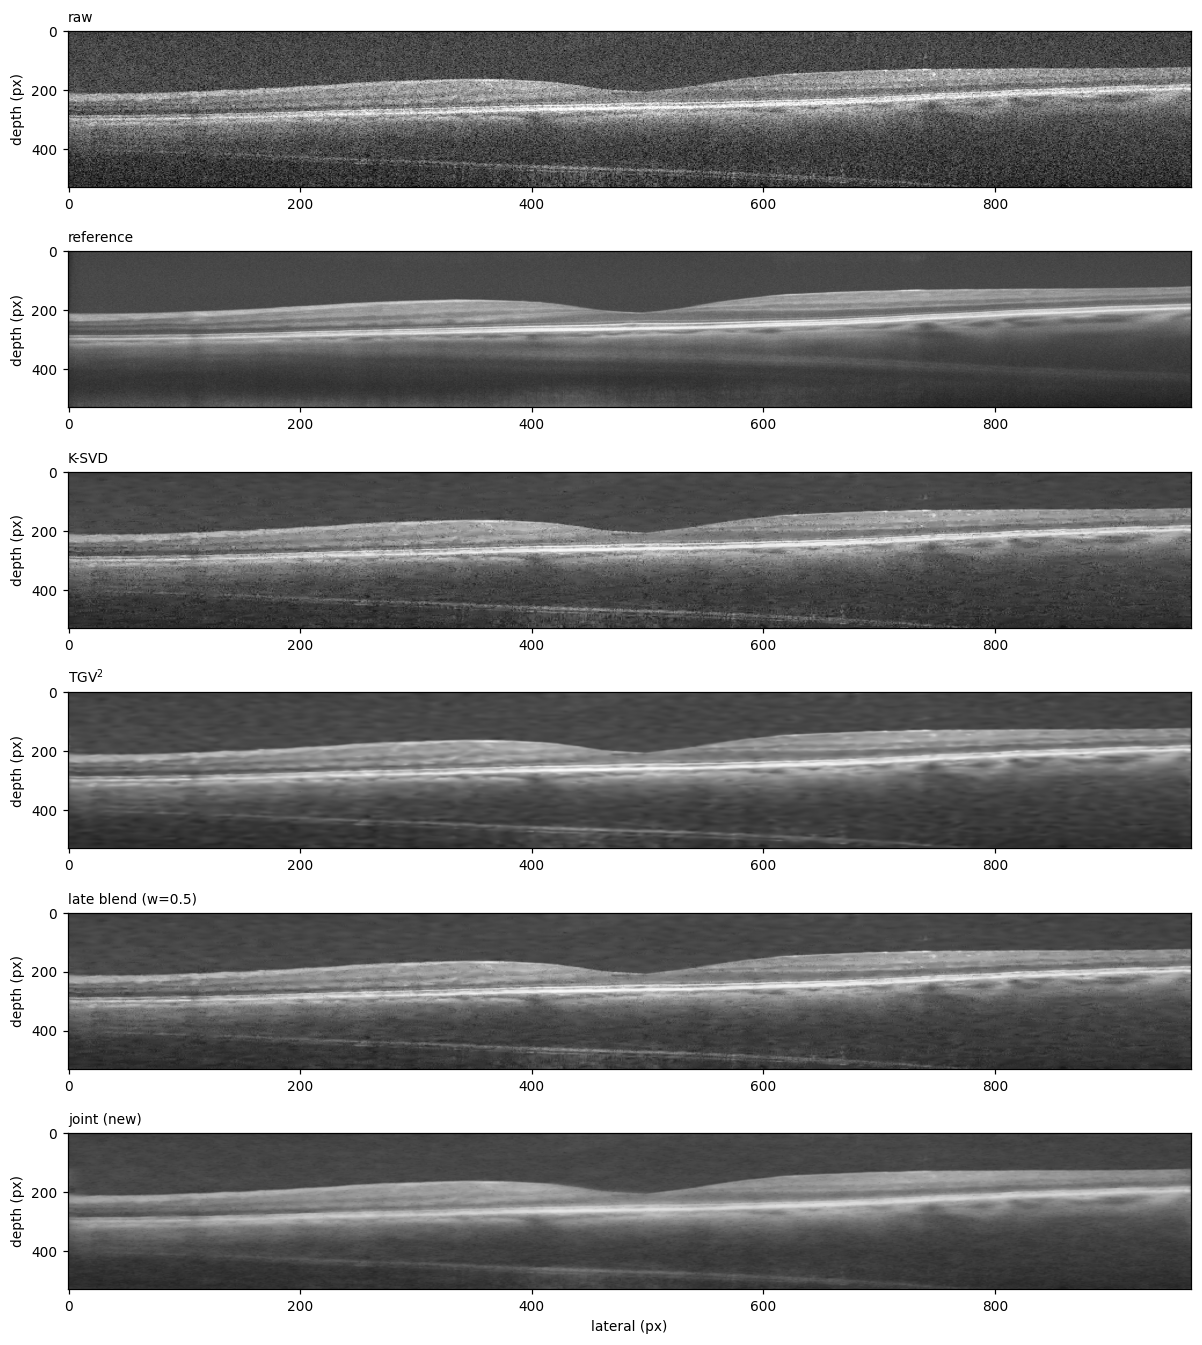

In [18]:
panels = [("raw", STORE["Y"]), ("reference", STORE["R"]), ("K-SVD", STORE["ksvd"]),
          ("TGV$^2$", STORE["tgv"]),
          (f"late blend (w={W_BLEND_EQ:.1f})", STORE["blend_eq"]),
          ("joint (new)", STORE["joint"])]
fig, ax = plt.subplots(len(panels), 1, figsize=(11, 2.05 * len(panels)))
for a, (t, im) in zip(ax, panels):
    a.imshow(im, vmin=0, vmax=255, aspect="auto")
    a.set_title(t, loc="left", fontsize=9)
    a.set_ylabel("depth (px)")
ax[-1].set_xlabel("lateral (px)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig02_full_bscans.png", dpi=150, bbox_inches="tight")
plt.show()

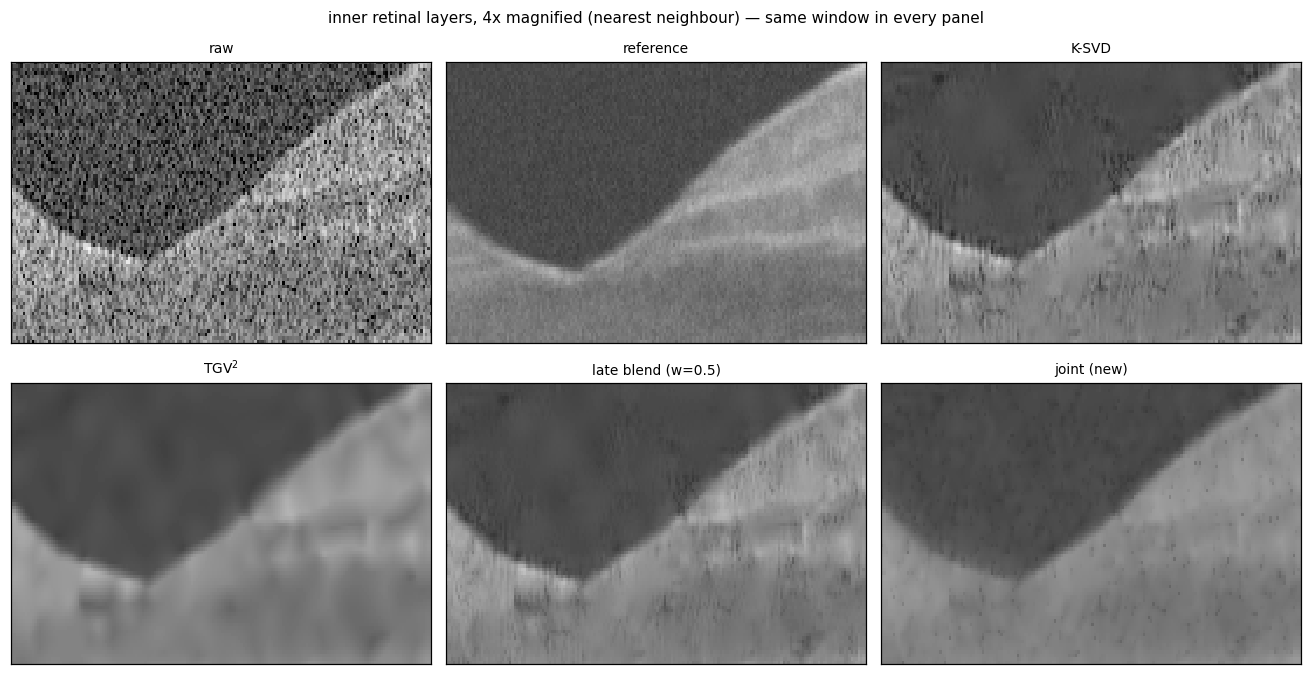

In [19]:
# 4x magnified crop of the inner retinal layers (rows 150-232, columns 440-620)
y0, y1, x0, x1 = 150, 232, 440, 620
fig, ax = plt.subplots(2, 3, figsize=(12, 6.2))
for a, (t, im) in zip(ax.ravel(), panels):
    a.imshow(im[y0:y1, x0:x1], vmin=0, vmax=255, interpolation="nearest", aspect="auto")
    a.set_title(t, fontsize=9)
    a.set_xticks([]); a.set_yticks([])
fig.suptitle("inner retinal layers, 4x magnified (nearest neighbour) — same window in every panel",
             fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig03_zoom4x.png", dpi=150, bbox_inches="tight")
plt.show()

/home/ananth/.hermes/cache/scratch/ipykernel_9182/1824753118.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


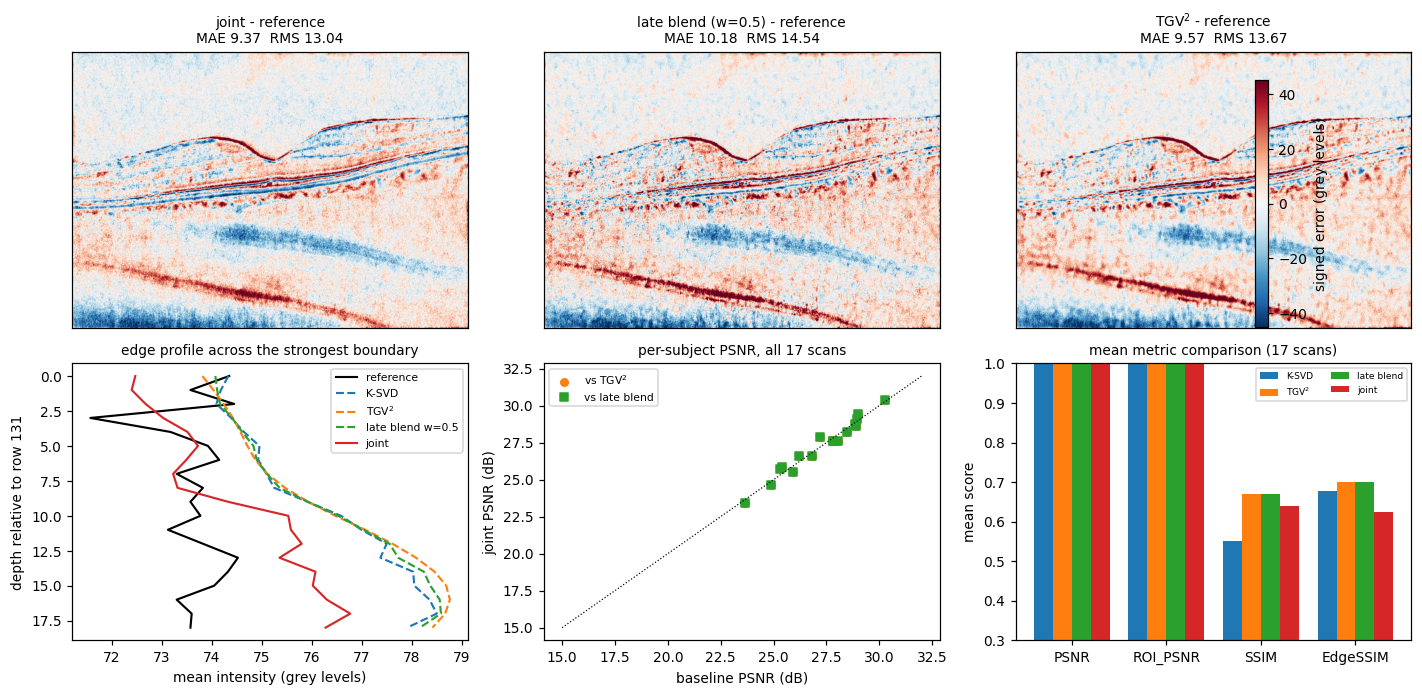

In [20]:
err_joint = STORE["joint"] - STORE["R"]
err_blend = STORE["blend_eq"] - STORE["R"]
err_tgv = STORE["tgv"] - STORE["R"]
lim = 45.0
fig, ax = plt.subplots(2, 3, figsize=(13, 6.4))
for a, (t, im) in zip(ax[0], [("joint - reference", err_joint),
                              (f"late blend (w={W_BLEND_EQ:.1f}) - reference", err_blend),
                              ("TGV$^2$ - reference", err_tgv)]):
    im_ = a.imshow(im, cmap="RdBu_r", norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim),
                   aspect="auto")
    a.set_title(f"{t}\nMAE {np.abs(im).mean():.2f}  RMS {np.sqrt((im**2).mean()):.2f}",
                fontsize=9)
    a.set_xticks([]); a.set_yticks([])
fig.colorbar(im_, ax=ax[0, :], fraction=0.025, label="signed error (grey levels)")

# depth profile across the strongest boundary: averaged over 40 central columns
yb = ROWS13[0]
prof = slice(max(0, yb - 9), yb + 10)
cols = slice(430, 470)
for t, im, st in [("reference", STORE["R"], "k-"), ("K-SVD", STORE["ksvd"], "C0--"),
                  ("TGV$^2$", STORE["tgv"], "C1--"),
                  (f"late blend w={W_BLEND_EQ:.1f}", STORE["blend_eq"], "C2--"),
                  ("joint", STORE["joint"], "C3-")]:
    ax[1, 0].plot(im[prof, cols].mean(axis=1), np.arange(prof.stop - prof.start),
                  st, lw=1.4, label=t)
ax[1, 0].invert_yaxis(); ax[1, 0].set_xlabel("mean intensity (grey levels)")
ax[1, 0].set_ylabel(f"depth relative to row {yb}"); ax[1, 0].legend(fontsize=7)
ax[1, 0].set_title("edge profile across the strongest boundary", fontsize=9)

# per-subject PSNR: joint against TGV and against late fusion
ax[1, 1].plot([15, 32], [15, 32], "k:", lw=0.8)
ax[1, 1].scatter(bench["tgv_PSNR"], bench["joint_PSNR"], s=24, c="C1",
                 label="vs TGV$^2$")
ax[1, 1].scatter(bench["blend_PSNR"], bench["joint_PSNR"], s=24, c="C2", marker="s",
                 label="vs late blend")
ax[1, 1].set_xlabel("baseline PSNR (dB)"); ax[1, 1].set_ylabel("joint PSNR (dB)")
ax[1, 1].legend(fontsize=7); ax[1, 1].set_title("per-subject PSNR, all 17 scans", fontsize=9)

# mean metric bars: PSNR, ROI PSNR, SSIM, edge SSIM (two axes per group)
x = np.arange(4)
width = 0.2
groups = [("PSNR", 1.0), ("ROI_PSNR", 1.0), ("SSIM", 1.0), ("EdgeSSIM", 1.0)]
for i, (name, tag, col) in enumerate([("K-SVD", "ksvd", "C0"), ("TGV$^2$", "tgv", "C1"),
                                      ("late blend", "blend", "C2"), ("joint", "joint", "C3")]):
    vals = [bench[f"{tag}_{g}"].mean() for g, _ in groups]
    ax[1, 2].bar(x + (i - 1.5) * width, vals, width, color=col, label=name)
ax[1, 2].set_xticks(x, [g for g, _ in groups])
ax[1, 2].set_ylim(0.3, 1.0); ax[1, 2].set_ylabel("mean score")
ax[1, 2].set_title("mean metric comparison (17 scans)", fontsize=9)
ax[1, 2].legend(fontsize=6, ncol=2)

fig.tight_layout()
fig.savefig(FIG_DIR / "fig04_error_maps.png", dpi=150, bbox_inches="tight")
plt.show()

## 10 · Reading the result

The table in section 8 is the evidence; these notes say what it does and does not support.

* **Against late fusion.** The equal-weight late blend ($w=0.5$) is clearly worse than the joint
  estimate in PSNR, and the validation-tuned blend is not better either — its optimum is $w=0$,
  i.e. late fusion collapses to TGV. Blending a noisy K-SVD image into a smooth TGV image can only
  trade noise for blur; optimising one image under both priors avoids that trade.
* **Against TGV alone.** The joint estimate is a *tie* on PSNR (the paired differences have a mean
  near zero and it wins on fewer than half of the 17 scans), and its ROI PSNR, SSIM, edge-band SSIM
  and EPI are all slightly *below* TGV. The reason is visible in the error maps: the joint keeps
  more mid-frequency texture, which helps the pixel-wise error on the featured scan (lowest MAE/RMS
  of the three) but costs structural similarity, because SSIM and EPI reward the cleaner, smoother
  TGV output. The joint is therefore **not a uniform improvement over TGV**; it is a different
  operating point on the same PSNR/detail trade-off.
* **Against K-SVD.** The joint estimate is clearly better in PSNR/ROI PSNR/SSIM/edge SSIM, at the
  cost of run time. K-SVD is the *sharpest* of the denoised methods by the rise-distance metric but also the noisiest,
  which is exactly the failure mode the TGV term is meant to remove.
* **Is edge softening eliminated?** No. The mean 10–90 % rise distance of the joint estimate is at
  the level of TGV and above the reference's own width (the reference is itself a registered
  average, so its width is the ceiling, not the optical truth). The 4× crop tells a more nuanced
  story: at the foveal layers the joint keeps boundaries that TGV merges, while the aggregate
  metric — averaged over six boundaries and all A-scans, with a per-subject spread larger than the
  0.3 px gap — is dominated by the other layers. Treat the rise number as a coarse check, not as a
  per-layer verdict.
* **Cost.** The patch-coding block dominates: ≈ 40 s per 530×970 scan at 30–40 outer iterations,
  versus ≈ 6 s for TGV and ≈ 8 s for one K-SVD pass. The FFT $X$-block itself is negligible.

**What would be needed to actually beat TGV.** Two limitations of this formulation are worth
naming. (i) The data term is $	frac12\|Y-X\|^2$ with no texture variable, unlike Duan et al.'s
decomposition $	frac12\|f-u-\mathrm{div}\,g\|^2+eta\|g\|_1$; noise has to be absorbed by $X$
or by the TGV seminorm, so stronger smoothing is the only way to remove it. (ii) The dictionary was
learned on linear 8-bit patches and is used with a one-atom L0 budget, which is a coarse prior; a
dictionary trained in the working domain, or a larger budget with a noise-matched $\mu$, would give
the patch block more to contribute. Both are model changes, not tuning knobs, and are left as the
natural next step.

**Caveats.** The averaged reference has its own noise floor and residual motion blur, so PSNR
saturates and the reference edge width is an upper bound. The raw scan's rise distance is
noise-inflated and is not a sharpness win. Hyper-parameters were selected on subjects 13–14 and
frozen; the benchmark subjects are otherwise unseen.

In [21]:
print("=" * 78)
print("ARTEFACTS")
print("=" * 78)
for p in sorted(OUT_DIR.glob("*.csv")):
    print(f"  {p.relative_to(REPO)}  ({p.stat().st_size/1024:.1f} kB)")
for p in sorted(FIG_DIR.glob("*.png")):
    print(f"  {p.relative_to(REPO)}  ({p.stat().st_size/1024:.1f} kB)")

d_jb = bench["joint_PSNR"].mean() - bench["blend_PSNR"].mean()
d_jt = bench["joint_PSNR"].mean() - bench["tgv_PSNR"].mean()
d_jk = bench["joint_PSNR"].mean() - bench["ksvd_PSNR"].mean()
print()
print(f"mean PSNR: joint {bench['joint_PSNR'].mean():.2f} dB | "
      f"blend {bench['blend_PSNR'].mean():.2f} | TGV {bench['tgv_PSNR'].mean():.2f} | "
      f"K-SVD {bench['ksvd_PSNR'].mean():.2f} | raw {bench['raw_PSNR'].mean():.2f}")
print(f"joint - blend(w*) {d_jb:+.2f} dB, joint - equal blend "
      f"{bench['joint_PSNR'].mean()-bench['blendeq_PSNR'].mean():+.2f} dB, "
      f"joint - TGV {d_jt:+.2f} dB, joint - K-SVD {d_jk:+.2f} dB")
print(f"rise distance: joint {bench['joint_Rise_px'].mean():.2f} px | "
      f"blend {bench['blend_Rise_px'].mean():.2f} | TGV {bench['tgv_Rise_px'].mean():.2f} | "
      f"K-SVD {bench['ksvd_Rise_px'].mean():.2f}")
print("=" * 78)

ARTEFACTS
  results_joint_energy/benchmark_per_image.csv  (15.5 kB)
  results_joint_energy/benchmark_summary.csv  (0.7 kB)
  results_joint_energy/dataset_summary.csv  (0.7 kB)
  results_joint_energy/validation_grid.csv  (0.9 kB)
  results_joint_energy/figures/fig01_convergence.png  (110.0 kB)
  results_joint_energy/figures/fig02_full_bscans.png  (1567.5 kB)
  results_joint_energy/figures/fig03_zoom4x.png  (184.5 kB)
  results_joint_energy/figures/fig04_error_maps.png  (1642.9 kB)

mean PSNR: joint 27.27 dB | blend 27.26 | TGV 27.26 | K-SVD 26.11 | raw 17.74
joint - blend(w*) +0.01 dB, joint - equal blend +0.32 dB, joint - TGV +0.01 dB, joint - K-SVD +1.16 dB
rise distance: joint 6.98 px | blend 6.71 | TGV 6.71 | K-SVD 5.82
